2    5    7    12    15    22    26    35    40
1 - x - x  + x  + x  - x   - x   + x   + x   - x   - x
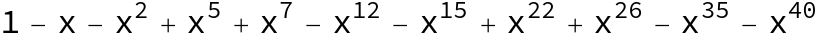

In [1]:
Sum[(-1)^n x^((3n^2-n)/2), {n,-5, 5}]

{13, 1}        {14}
{12, 2}        {11, 2, 1}
{11, 3}        {10, 3, 1}
{10, 4}        {9, 4, 1}
{9, 5}         {9, 3, 2}
{8, 6}         {8, 5, 1}
{8, 3, 2, 1}   {8, 4, 2}
{7, 4, 2, 1}   {7, 6, 1}
{6, 5, 2, 1}   {7, 5, 2}
{6, 4, 3, 1}   {7, 4, 3}
{5, 4, 3, 2}   {6, 5, 3}
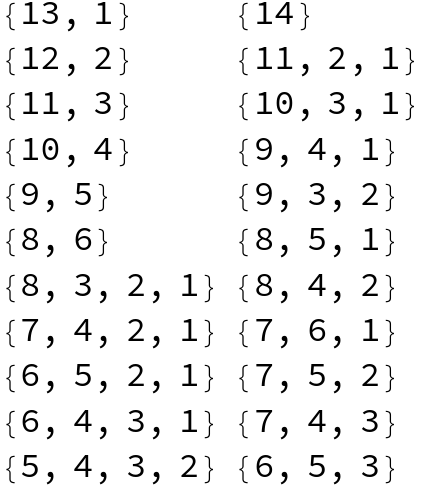

In [4]:
DistinctPartitions[n_] := 
  Select[IntegerPartitions[n], Length[#] == Length[Union[#]] &];

EvenOdd[n_] := 
 With[{dp = DistinctPartitions[n]}, 
  Grid[{Column[Select[dp, #]] & /@ {EvenQ@*Length, OddQ@*Length}}, 
   Alignment -> Top]]; 

EvenOdd[14]

{15}
{14, 1}        {12, 2, 1}
{13, 2}        {11, 3, 1}
{12, 3}        {10, 4, 1}
{11, 4}        {10, 3, 2}
{10, 5}        {9, 5, 1}
{9, 6}         {9, 4, 2}
{9, 3, 2, 1}   {8, 6, 1}
{8, 7}         {8, 5, 2}
{8, 4, 2, 1}   {8, 4, 3}
{7, 5, 2, 1}   {7, 6, 2}
{7, 4, 3, 1}   {7, 5, 3}
{6, 5, 3, 1}   {6, 5, 4}
{6, 4, 3, 2}   {5, 4, 3, 2, 1}
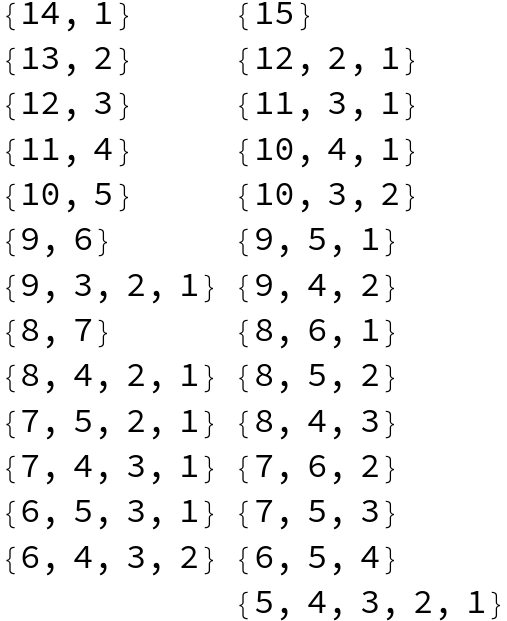

In [5]:
EvenOdd[15]

9       -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-
         
        >       -Graphics-   -Graphics-   -Graphics-



8+1     -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-
         
        >       -Graphics-   -Graphics-

        -Graphics-
         
        >    



7+2     -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-
         
        >       -Graphics-

        -Graphics-   -Graphics-
         
        >    



6+3     -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-

        -Graphics-   -Graphics-   -Graphics-





6+2+1   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-

        -Graphics-   -Graphics-

        -Graphics-



5+4     -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-

        -Graphics-   -Graphics-   -Graphics-   -Graphics-





5+3+1   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-

        -Graphics-   -Graphics-   -Graphics-

        -Graphics-





4+3+2   -Graphics-   -Graphics-   -Graphics-   -Graphics-

        -Graphics-   -Graphics-   -Graphics-

        -Graphics-   -Graphics-
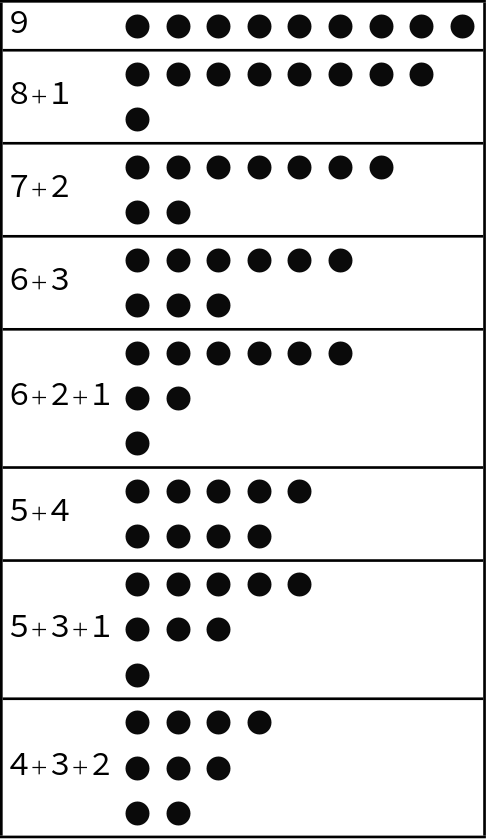

In [7]:
YoungDiagram[xs_] := Grid[Table[Graphics[Disk[], ImageSize -> 10], #] & /@ ReverseSort[xs]];

Grid[Table[{StringRiffle[ToString /@ p, "+"], YoungDiagram[p]}, {p, DistinctPartitions[9]}], Dividers -> {True, All}, Alignment -> Left]

-Graphics-   -Graphics-   -Graphics-   -Graphics-

-Graphics-   -Graphics-   -Graphics-

-Graphics-   -Graphics-
 


     -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-

>    -Graphics-   -Graphics-   -Graphics-   -Graphics-
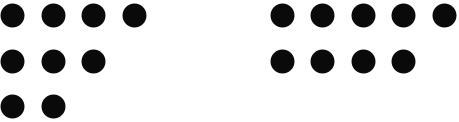

In [8]:
Grid[{YoungDiagram /@ {{4, 3, 2}, {5, 4}}}, Alignment -> Top, ColumnSpacings -> 5]

-Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphic\
 
>    s-   -Graphics-   -Graphics-
 
        -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-
         
        >       -Graphics-   -Graphics-

        -Graphics-
         
>       >    

-Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-

-Graphics-   -Graphics-
 
>       -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-

        -Graphics-   -Graphics-

        -Graphics-

-Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphic\
                                                                               
-Graphics-   -Graphics-   -Graphics-                                          >    s-
                                                                               
                                                                              >       -G\
                                                                               
                                                                              >    raphi\
                                                                               
                                                                              >    cs-
                                                                               
                                                                              >       -G\
                                                                               
                                                                              >    raphi\
                                                                               
                                                                              >    cs-
                                                                               
                                                                              >       -G\
                                                                               
                                                                              >    raphi\
                                                                               
                                                                              >    cs-
                                                                               
                                                                              >       -G\
                                                                               
                                                                              >    raphi\
                                                                               
                                                                              >    cs-

                                                                              -Graphic\
                                                                               
                                                                              >    s-
                                                                               
                                                                              >       -G\
                                                                               
                                                                              >    raphi\
                                                                               
                                                                              >    cs-
                                                                               
                                                                              >       -G\
                                                                               
                                                                              >    raphi\
                                                         
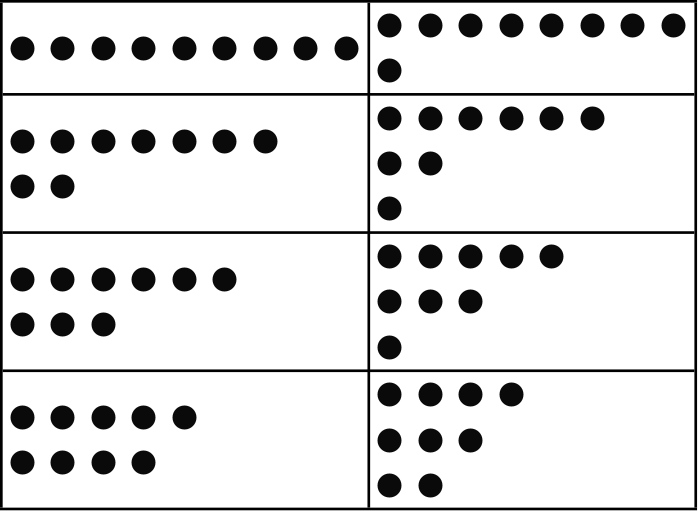

In [12]:
DiagonalLength[xs_] := With[{fp = FirstPosition[First[xs] + 1 - Range@Length[xs] - xs, x_ /; x > 0]}, 
    If[MissingQ[fp], Length[xs], fp[[1]] - 1]
  ];
PartitionPair[xs_] := 
  Sort[{xs, 
    If[DiagonalLength[xs] < Last[xs], 
     Append[xs - PadRight[Table[1, DiagonalLength[xs]], Length[xs]], DiagonalLength[xs]], 
     Most[xs] + PadRight[Table[1, Last[xs]], Length[xs] - 1]
    ]
  }];
Pairing[n_] := Grid[Map[YoungDiagram, Values[GroupBy[DistinctPartitions[n], PartitionPair]], {2}], Alignment -> Left, Dividers -> {All, All}]

Pairing[9]

-Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphic\
 
>    s-
 
        -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-

>       -Graphics-

-Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-

-Graphics-   -Graphics-
 
     -Graphics-   -Graphics-   -Graphics-   -Graphics-

     -Graphics-   -Graphics-

>    -Graphics-

-Graphics-   -Graphics-   -Graphics-   -Graphics-

-Graphics-   -Graphics-   -Graphics-
 


>
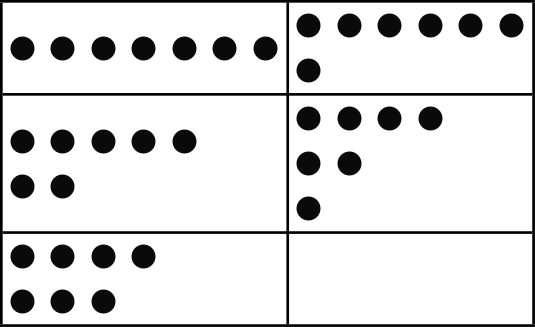

In [13]:
Pairing[7]

-Graphics-   -Graphics-   -Graphics-

-Graphics-   -Graphics-   -Graphics-
 
                                                                      -Graphics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-

                                                                      -Graphics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-
                                                                       
                                                                      >    

                                                                      -Graphics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-
                                                                       
                                                                      >    
                                                                       
                                                                      >    

                                                                      -Graphics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-   -Grap\
                                                                       
                                                                      >    hics-
                                                                       
                                                                      >    
                                                                       
     -Graphics- 
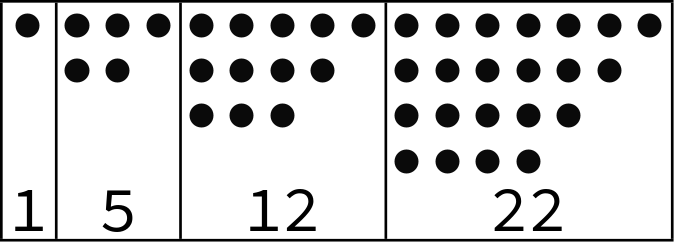

In [14]:
Grid[Transpose[
  Table[{YoungDiagram[Range[2 n - 1, n, -1]], 
    Style[Total@Range[2 n - 1, n, -1], 24]}, {n, 1, 4}]], 
 Alignment -> Top, Dividers -> {All, True}]

-Graphics-   -Graphics-   -Graphics-   -Graphics-

-Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-
 
     -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-

     -Graphics-   -Graphics-   -Graphics-   -Graphics-   -Graphics-

>    -Graphics-   -Graphics-   -Graphics-   -Graphics-

2                         7
 
>    15
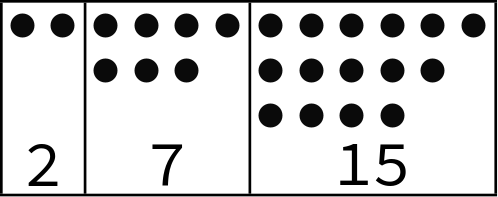

In [15]:
Grid[Transpose[
  Table[{YoungDiagram[Range[2 n - 2, n, -1]], 
    Style[Total@Range[2 n - 2, n, -1], 24]}, {n, 2, 4}]], 
 Alignment -> Top, Dividers -> {All, True}]

In [10]:
ResourceFunction["MaTeXInstall"][];
<< MaTeX`
SetOptions[MaTeX, "Preamble" -> {"\\usepackage{amsfonts}"}];
texStyle = 
  Sequence @@ {BaseStyle -> {FontFamily -> "CMU Serif", 
      FontSize -> 16}, TicksStyle -> Directive[30], 
    FrameTicksStyle -> Directive[30], LabelStyle -> Black, 
    AxesStyle -> Black, FrameStyle -> Black, PlotStyle -> Black};

-Graphics-
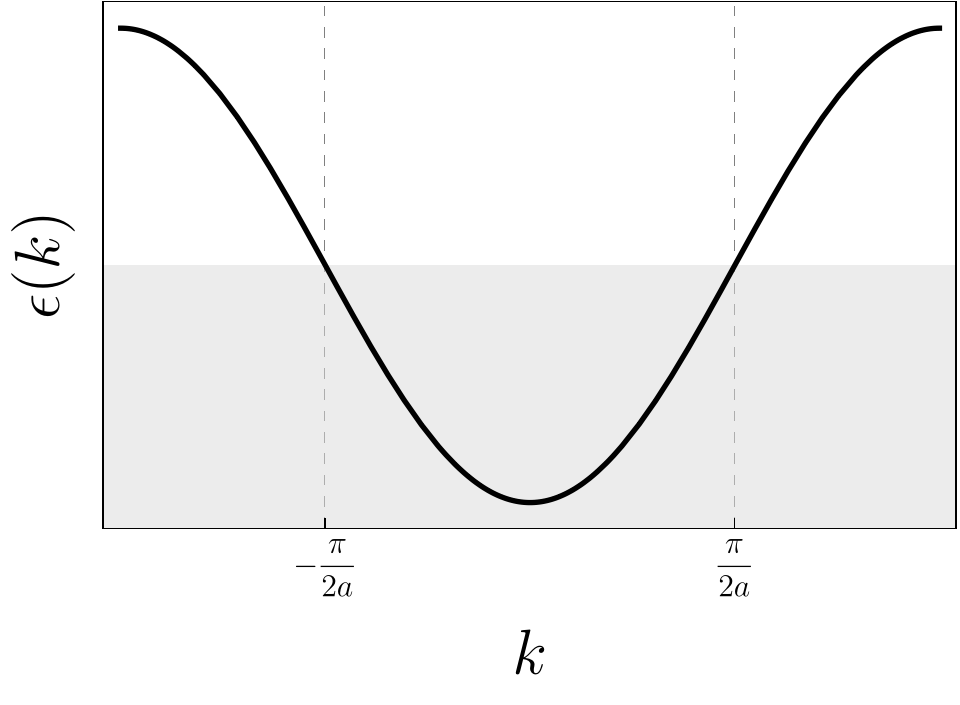

In [20]:
Plot[-Cos[ka], {ka, -Pi, Pi}, Axes -> False, Frame -> True, 
 FrameTicks -> {{None, 
    None}, {{{-Pi/2, MaTeX["-\\frac{\\pi}{2a}"]}, {Pi/2, 
      MaTeX["\\frac{\\pi}{2a}"]}}, None}}, 
 FrameLabel -> {MaTeX["k", Magnification -> 2], 
   MaTeX["\\epsilon(k)", Magnification -> 2]}, 
 Prolog -> {LightGray, Opacity[0.5], 
   Rectangle[Scaled[{0, 0}], Scaled[{1, 0.5}]]}, 
 GridLines -> {{-Pi/2, Pi/2}, None}, 
 GridLinesStyle -> Directive[Dashed], Evaluate@texStyle]

-Graphics-
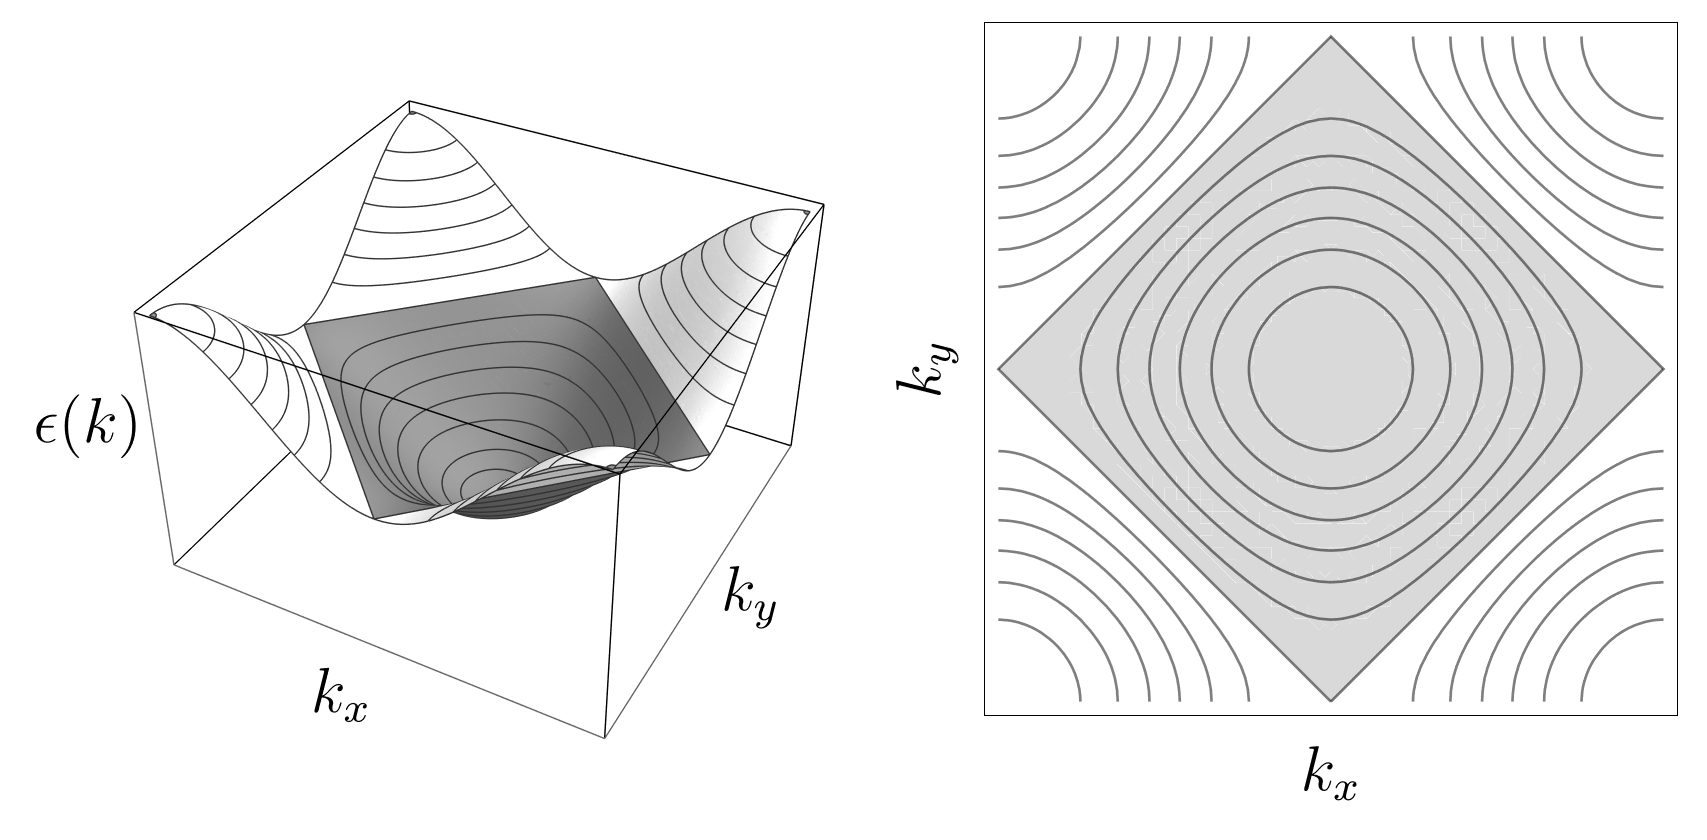

In [21]:
GraphicsRow[{Show[
   SliceContourPlot3D[z, 
    z == -Cos[kxa] - Cos[kya], {kxa, -Pi, Pi}, {kya, -Pi, Pi}, {z, -2,
      2}, BoxRatios -> Automatic, 
    ContourShading -> Join[Table[Gray, 8], Table[White, 7]], 
    Contours -> Subdivide[-2, 2, 14], LabelStyle -> Black, 
    BoxStyle -> Black, Ticks -> None], 
   AxesLabel -> {MaTeX["k_x", Magnification -> 2], 
     MaTeX["k_y", Magnification -> 2], 
     MaTeX["\\epsilon(k)", Magnification -> 2]}], 
  ContourPlot[-Cos[kxa] - Cos[kya], {kxa, -Pi, Pi}, {kya, -Pi, Pi}, 
   Axes -> False, Frame -> True, FrameTicks -> None, 
   FrameLabel -> {MaTeX["k_x", Magnification -> 2], 
     MaTeX["k_y", Magnification -> 2]}, 
   ContourShading -> Join[Table[LightGray, 8], Table[White, 7]], 
   Contours -> Subdivide[-2, 2, 14], Evaluate@texStyle]}]

{0   1   0, 0   0   0, 0   0   1, 0   0   0, 0   0   0, 0   0   0, 1    0    0 , 

 0   0   0  1   0   0  0   0   0  0   0   0  0   0   1  0   0   0  0    -1   0

 0   0   0  0   0   0  0   0   0  1   0   0  0   0   0  0   1   0  0    0    0
 
>   0    0    0 }

    0    1    0

    0    0    -1
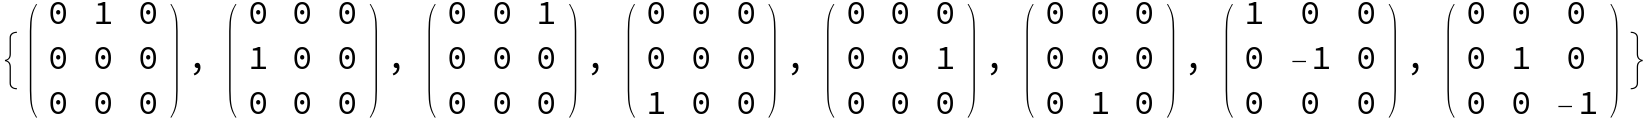

In [23]:
sl3 = Join[
   Table[SparseArray[{ij -> 1}, {3, 3}], {ij, 
     Flatten[Permutations /@ Subsets[Range[3], {2}], 1]}], 
   DiagonalMatrix /@ {{1, -1, 0}, {0, 1, -1}}];
MatrixForm /@ sl3

{2    0    0    0    0    0    0    0 , -1   0    0    0    0    0    0    0 }

 0    -2   0    0    0    0    0    0   0    1    0    0    0    0    0    0

 0    0    1    0    0    0    0    0   0    0    1    0    0    0    0    0

 0    0    0    -1   0    0    0    0   0    0    0    -1   0    0    0    0

 0    0    0    0    -1   0    0    0   0    0    0    0    2    0    0    0

 0    0    0    0    0    1    0    0   0    0    0    0    0    -2   0    0

 0    0    0    0    0    0    0    0   0    0    0    0    0    0    0    0

 0    0    0    0    0    0    0    0   0    0    0    0    0    0    0    0
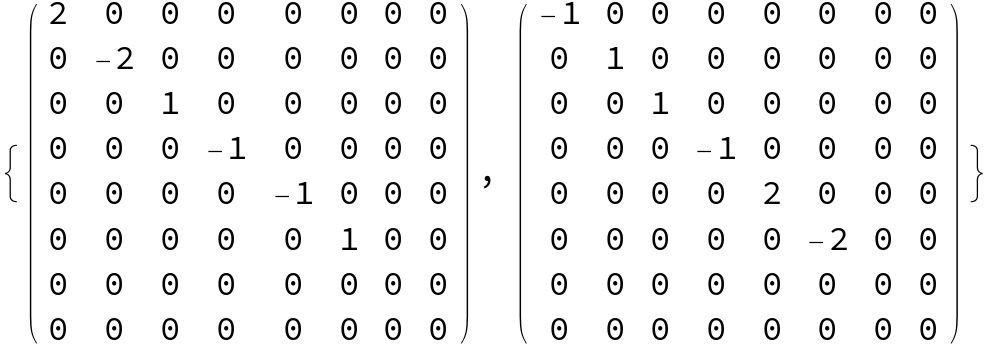

In [27]:
cartan = sl3[[-2 ;;]];
coeffs[mat_, mats_] := 
  LinearSolve[Transpose[Flatten /@ mats], Flatten[mat]];
adjoints = Table[coeffs[h . g - g . h, sl3], {h, cartan}, {g, sl3}];
MatrixForm /@ adjoints

-Graphics-
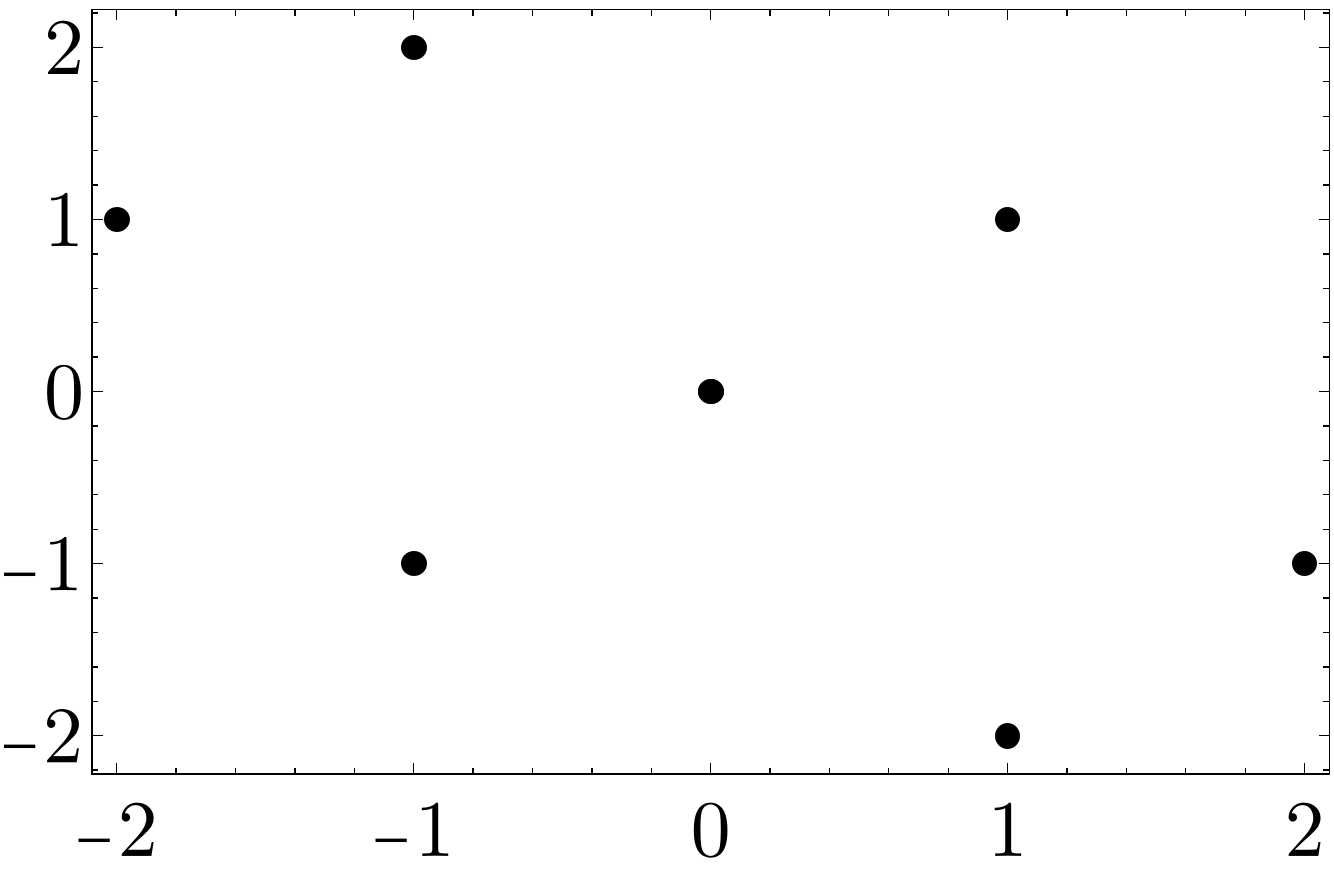

In [28]:
ListPlot[Transpose[
  Diagonal /@ adjoints], 
 Axes -> False, Frame -> True, PlotStyle -> {Black, PointSize[.02]}, 
 ImageSize -> 500, Evaluate@texStyle]

-Graphics-
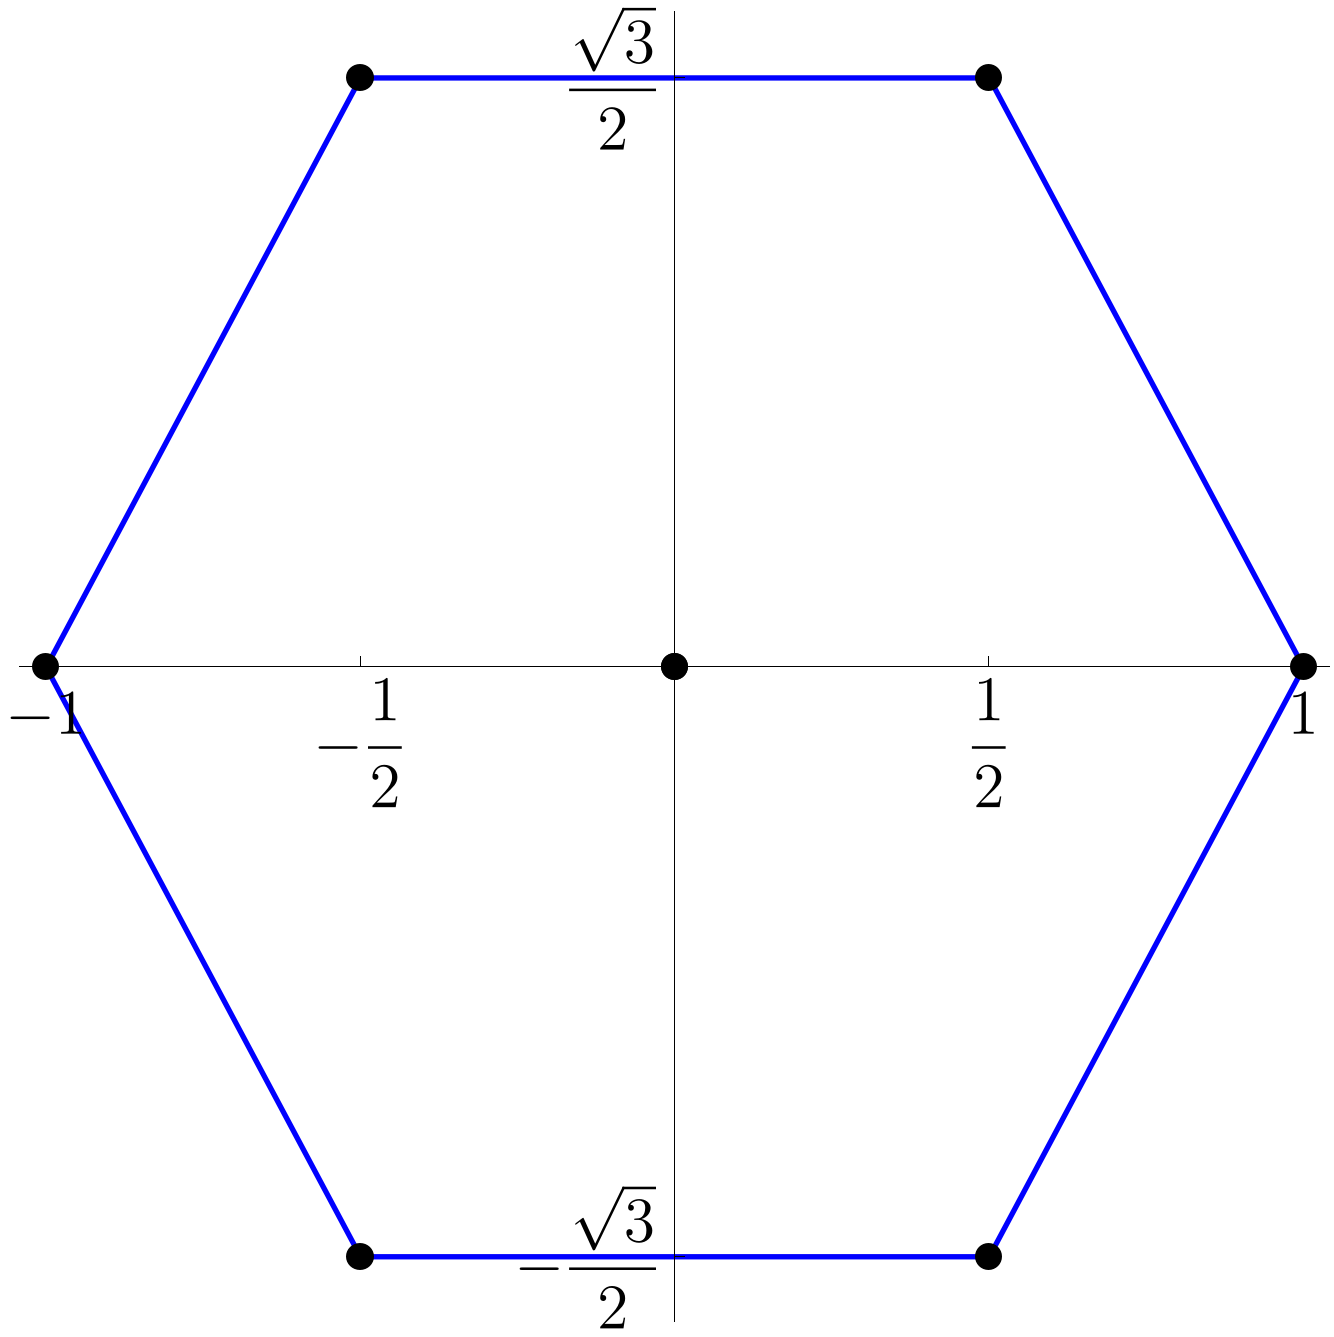

In [30]:
roots = Transpose[Diagonal /@ (( {
       {0, -1/2},
       {Sqrt[3]/3, Sqrt[3]/6}
      } ) . adjoints)];
hexagon = ListPlot[roots, 
 Ticks -> {Thread[{#, MaTeX[#, Magnification -> 2]} &@{-1, -1/2, 1/2, 
      1}], Thread[{#, MaTeX[#, Magnification -> 2]} &@{-Sqrt[3]/2, 
      Sqrt[3]/2}]}, PlotStyle -> {Black, PointSize[.02]}, 
 AspectRatio -> 1, ImageSize -> 500, 
 Prolog -> {FaceForm[], EdgeForm[{Thick, Blue}], RegularPolygon[6]}, 
 Evaluate@texStyle]

{       ,   1         , 1           }
          -(-)          -
 0          2           2

    1       1     1       1     1
 -------  -(-) -------  -(-) -------
 Sqrt[3]    2  Sqrt[3]    2  Sqrt[3]
Legended[-Graphics-, Placed[PointLegend[{GrayLevel[0], RGBColor[1, 0, 0]}, 
 
>     {Roots, Weights}, Joined -> {False}, LabelStyle -> {}, LegendFunction -> Frame, 
 
>     LegendLayout -> Column, LegendMarkers -> {{False, Automatic}}], After, Identity]]
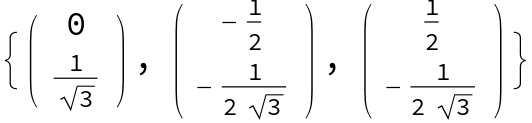
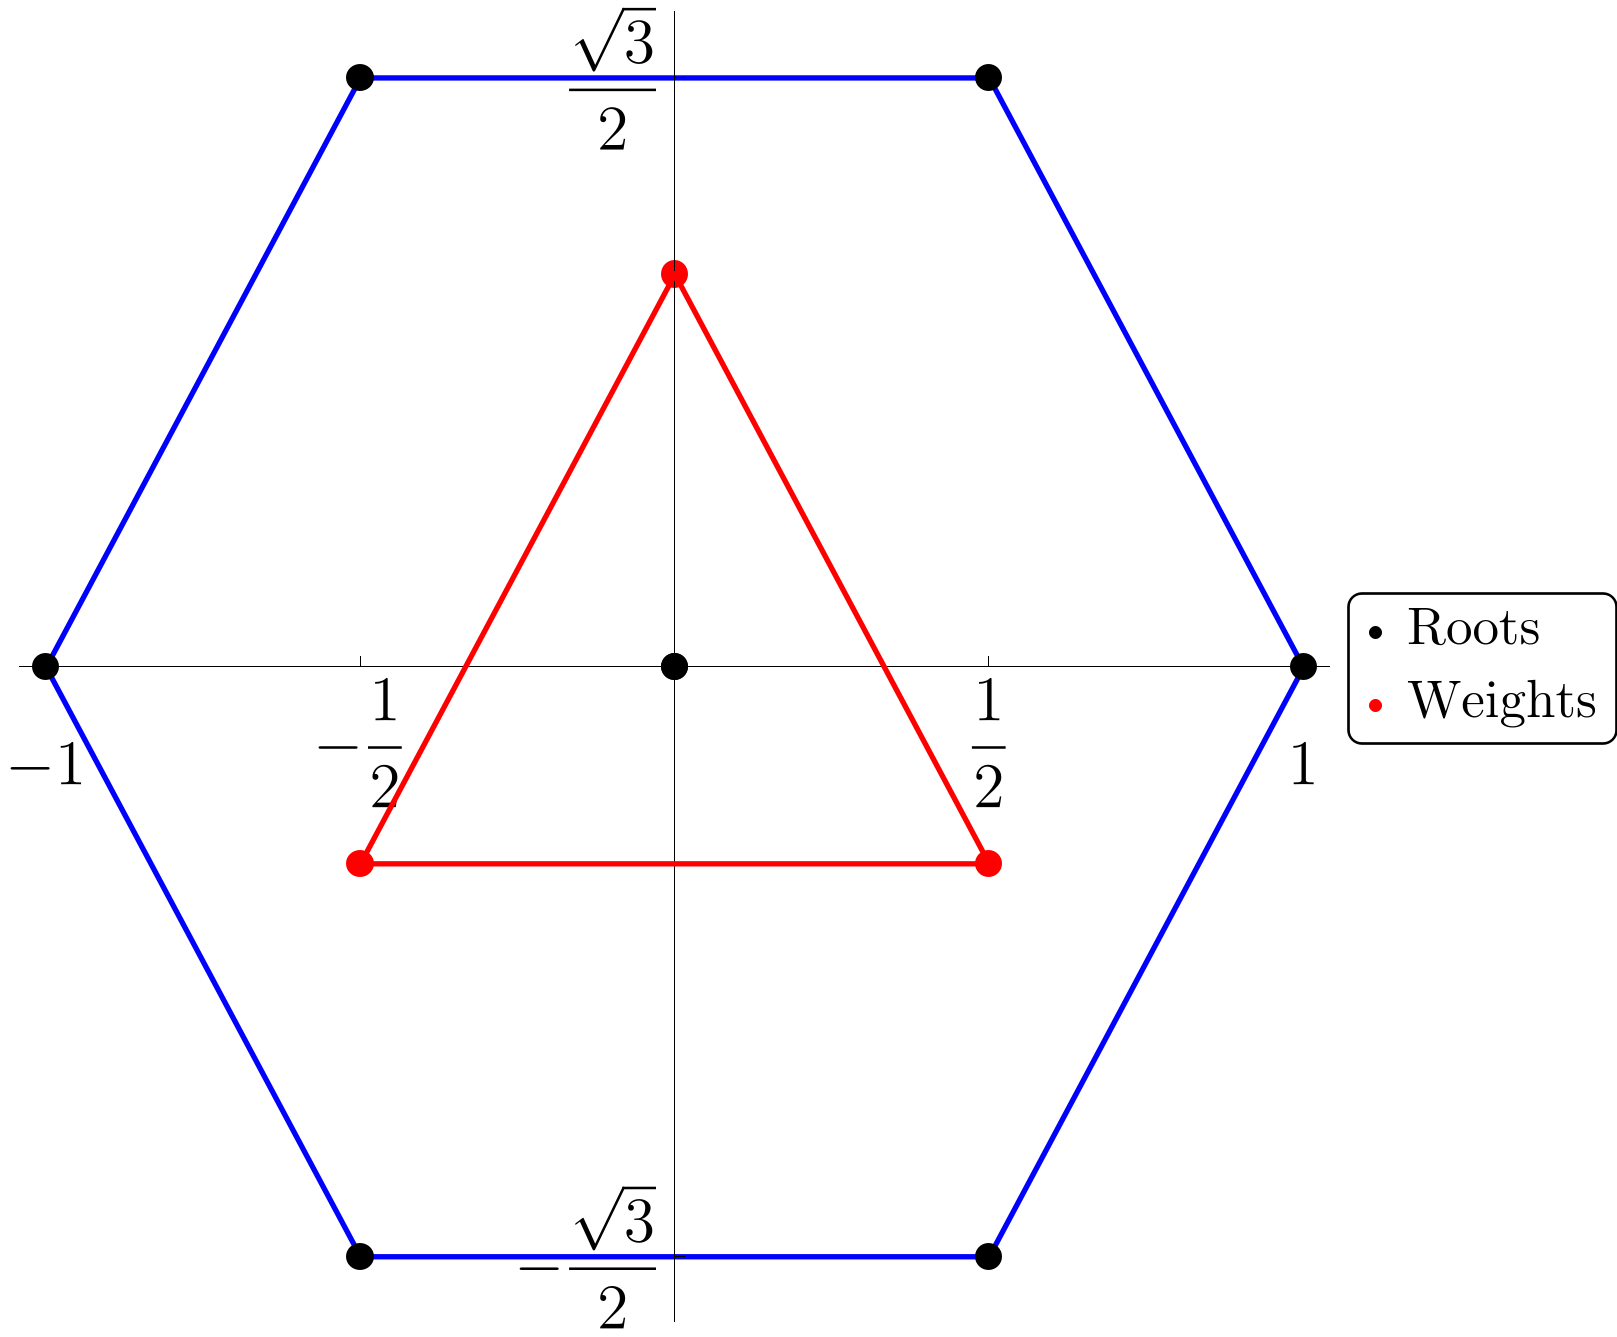

In [32]:
weights = Transpose[Diagonal /@ (( {
       {0, -1/2},
       {Sqrt[3]/3, Sqrt[3]/6}
      } ) . cartan)];
MatrixForm /@ weights
Show[hexagon, 
 ListPlot[weights, PlotStyle -> {Red, PointSize[.02]}, 
  PlotLegends -> 
   PointLegend[{Black, Red}, 
    Evaluate[
     Style[#, 20, FontFamily -> "CMU Serif"] & /@ {"Roots", 
       "Weights"}], LegendFunction -> "Frame"]], 
 Epilog -> {EdgeForm[{Thick, Red}], FaceForm[], Polygon[weights]}]

-Graphics-
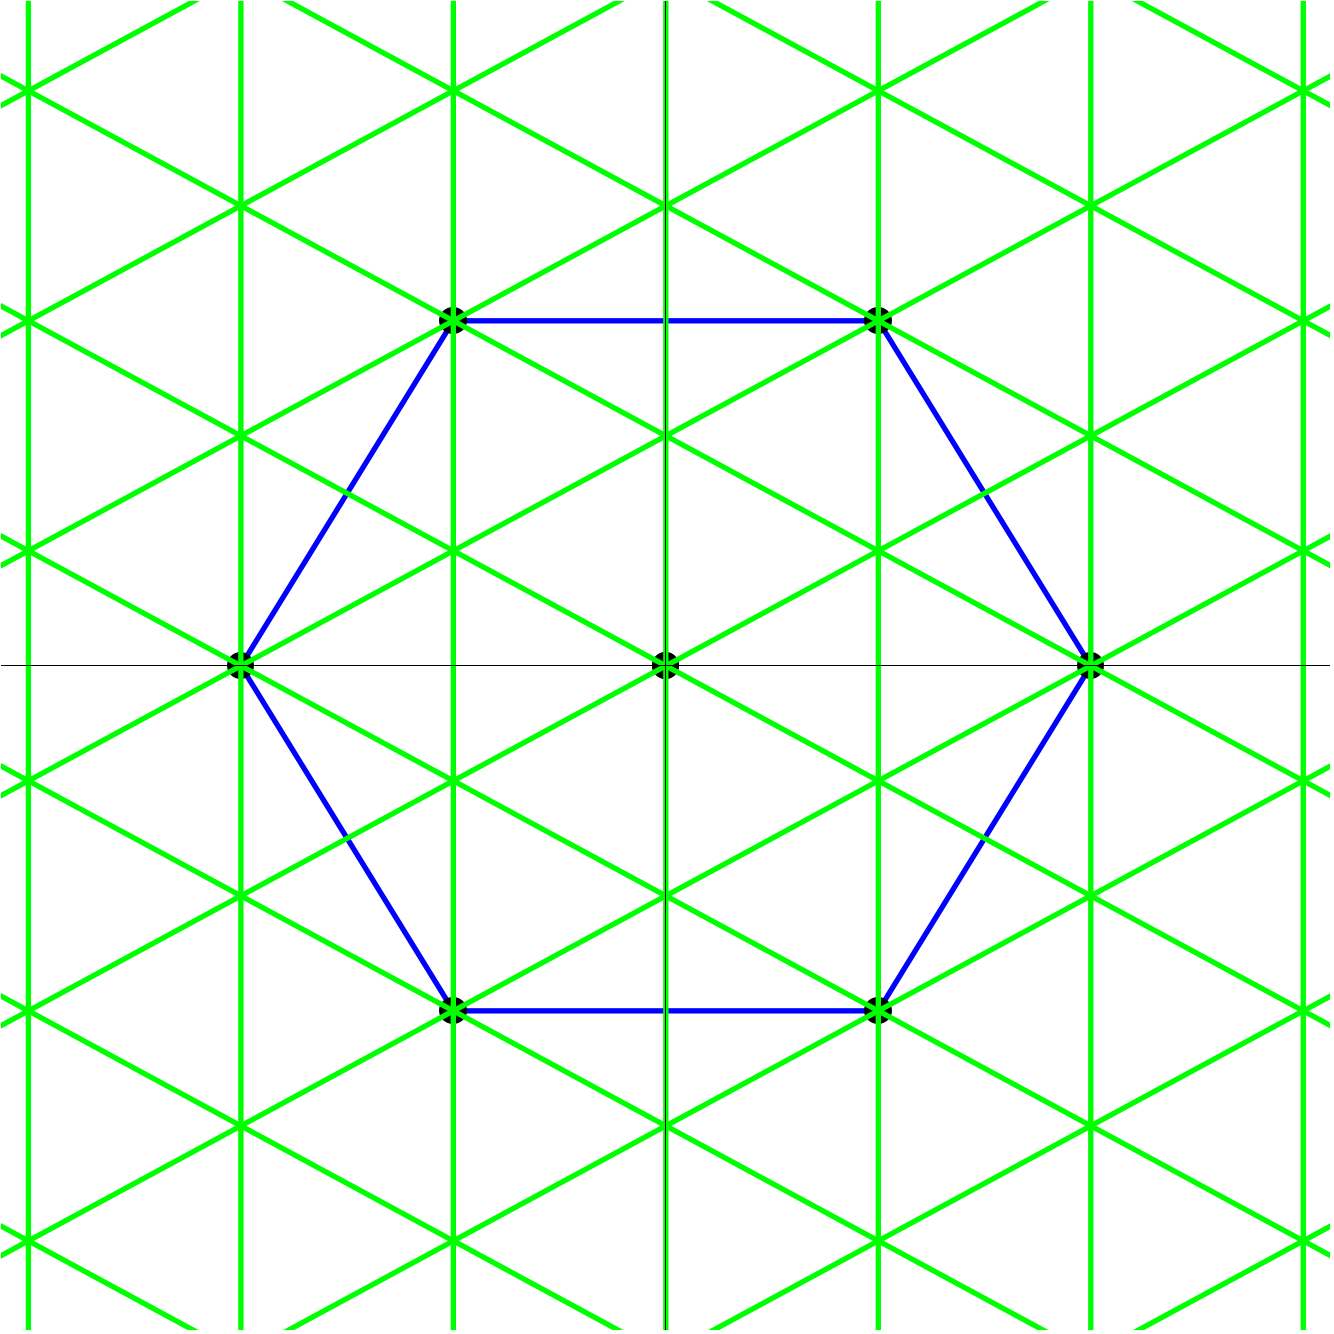

In [35]:
lattice = Normal[Plot[
  Table[Tan[\[Theta]] x - 0.5 shift Sec[\[Theta]], {\[Theta], 0, 
    2 Pi/3, Pi/3}, {shift, -7, 7}], {x, -4, 4}, Axes -> False, 
  AspectRatio -> Full, PlotStyle -> Green], Pi/6] /. 
prim : _Line | _Point | _Polygon :> 
  GeometricTransformation[prim, RotationTransform[Pi/6]];

Show[hexagon, lattice, 
 PlotRange -> {{-1.5, 1.5}, {-1.5, 1.5}}, Ticks -> None]

-Graphics-
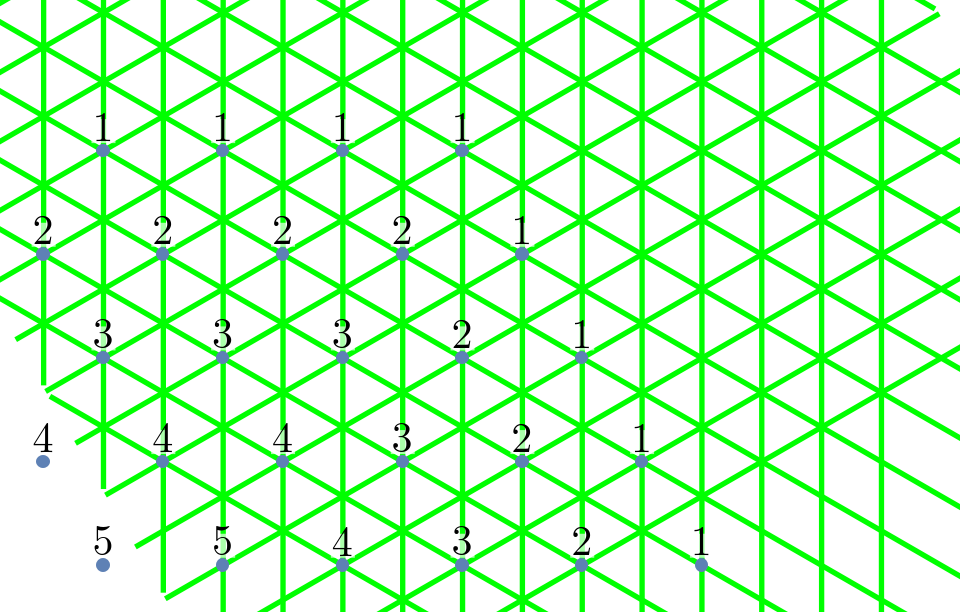

In [38]:
a1 = {1, 0};
a2 = {-1/2, Sqrt[3]/2};

Show[lattice, 
 ListPlot[Flatten@
   Table[Labeled[-m a1 - n a2, 
     Style[Min[m, n] + 1, 16, FontFamily -> "CMU Serif"], Above], {m, 
     0, 5}, {n, 0, 5}]], PlotRange -> {{-3.7, 4}, {-3.6, 1}}, 
 AspectRatio -> Automatic, Background -> Transparent]

In [20]:
isPositive[{x_, y_}] := 0 <= ArcTan[y, x] <= 2 Pi/3;

simpleRoots = Transpose[{a1, a2}];
fundWeights = {{0, 1/2}, {1/Sqrt[3], Sqrt[3]/6}};

fromRoots[{x_, y_}] := simpleRoots . {x, y};
toRoots[{x_, y_}] := Inverse[simpleRoots] . {x, y};
fromWeights[{x_, y_}] := fundWeights . {x, y};
toWeights[{x_, y_}] := Inverse[fundWeights] . {x, y};

weyl = Join[Table[RotationMatrix[2 n Pi/3], {n, 3}], 
   Table[ReflectionMatrix[{Cos[n Pi/3], Sin[n Pi/3]}], {n, 1, 5, 2}]];
eweyl = {1, 1, 1, -1, -1, -1};

\[Rho] = fromRoots[{1, 1}];

In [21]:
numerator[m_, n_] := 
  Thread[{Table[w . (\[Rho] + fromWeights[{m, n}]), {w, weyl}], 
    eweyl}];
hull[m_, n_] := ConvexHullRegion[First /@ numerator[m, n]];

pts[m_, n_] := 
  With[{mem = RegionMember[hull[m, n]]}, 
   fromWeights /@ 
    Select[Tuples@*
       List @@ (Range @@@ 
        Simplify@
         RegionBounds[
          ConvexHullRegion[toWeights /@ (First /@ numerator[m, n])]]),
      mem[fromWeights[#]] &]
   ];

ct[{x_, y_}] := With[{rt = Simplify@toRoots[{x, y}]},
   If[! AllTrue[rt, # >= 0 && IntegerQ[#] &], 0, Min @@ rt + 1]
   ];

char[m_, n_] := 
  Select[Thread[{pts[m, n], 
     Table[Sum[hex[[2]] ct[hex[[1]] - p], {hex, numerator[m, n]}], {p,
        pts[m, n]}]}], #[[2]] != 0 &];

charPlot[m_, n_] := 
 ListPlot[Labeled[#1, Style[#2, 20, FontFamily -> "CMU Serif"], 
     Above] & @@@ char[m, n], Axes -> False, AspectRatio -> Automatic,
   Background -> Transparent, texStyle]

-Graphics-
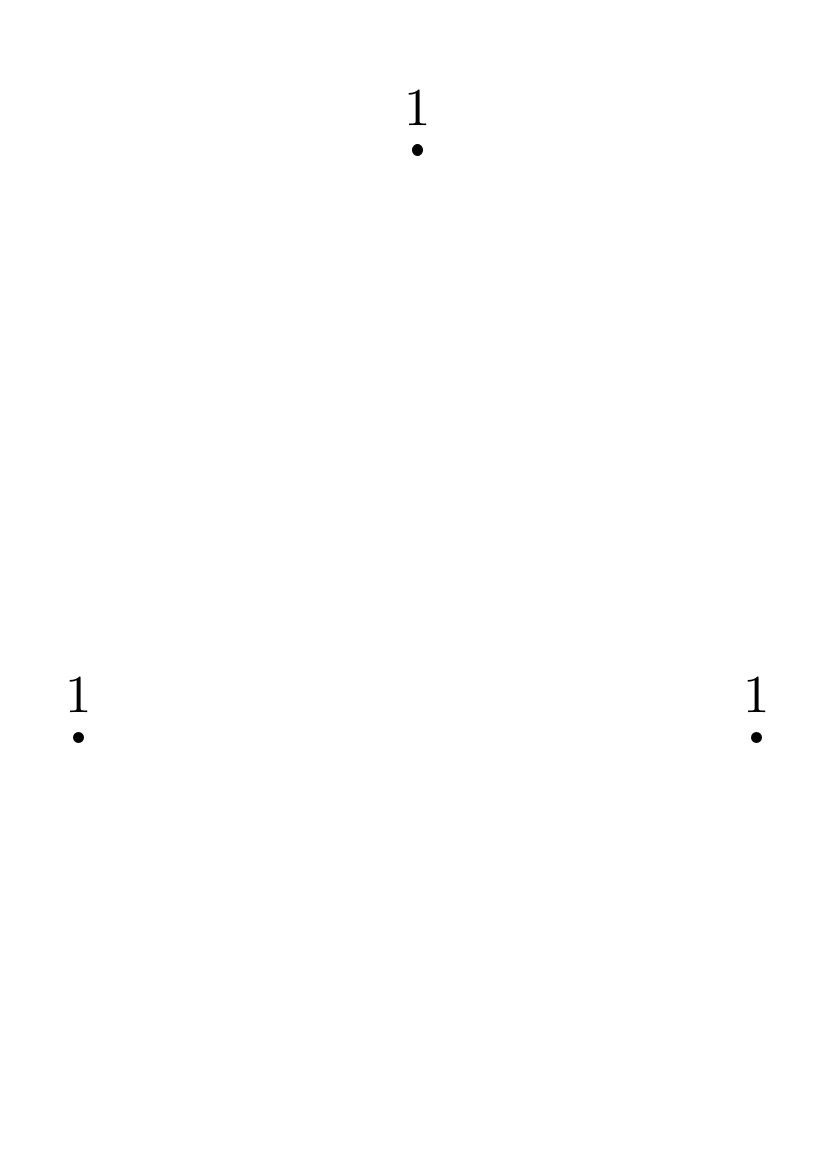

In [55]:
charPlot[1,0]

-Graphics-
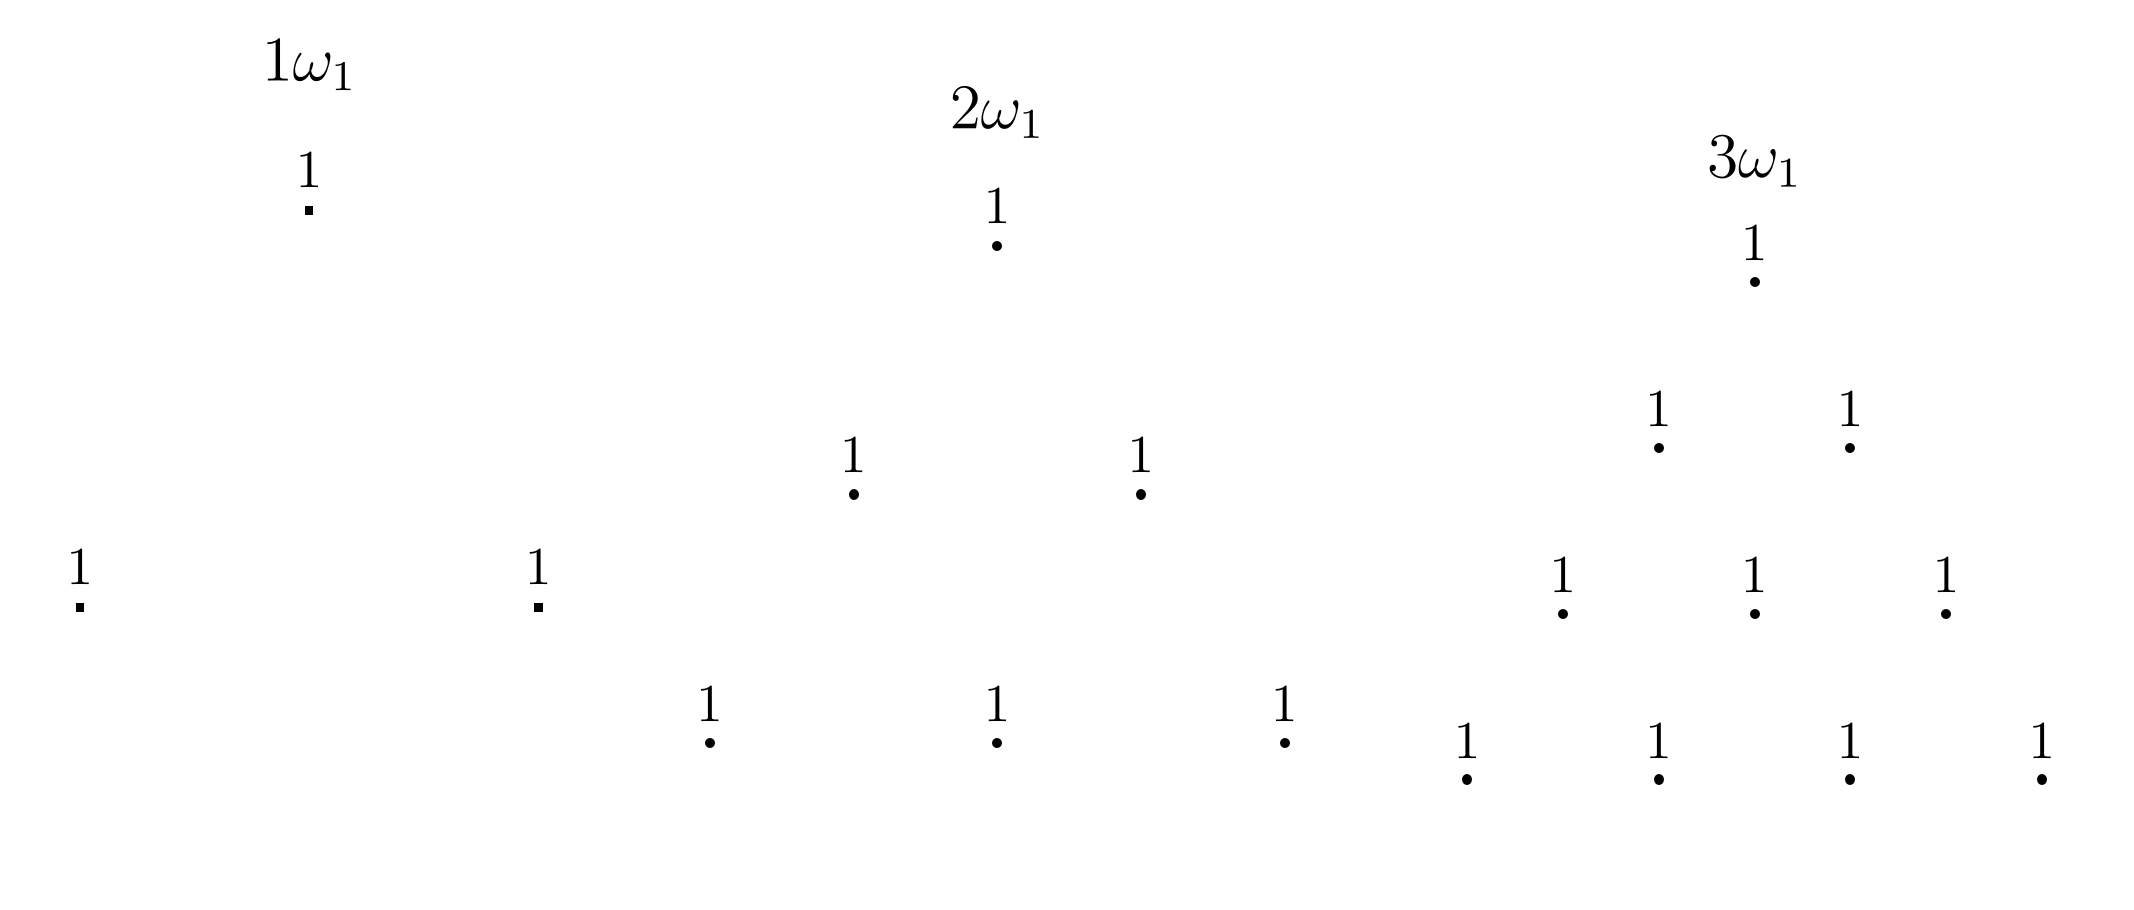

In [56]:
GraphicsRow[
 Table[Show[charPlot[n, 0], 
   PlotLabel -> 
    MaTeX[ToString[n] <> "\\omega_1", Magnification -> 2]], {n, 3}], 
 ImageSize -> 800]

-Graphics-
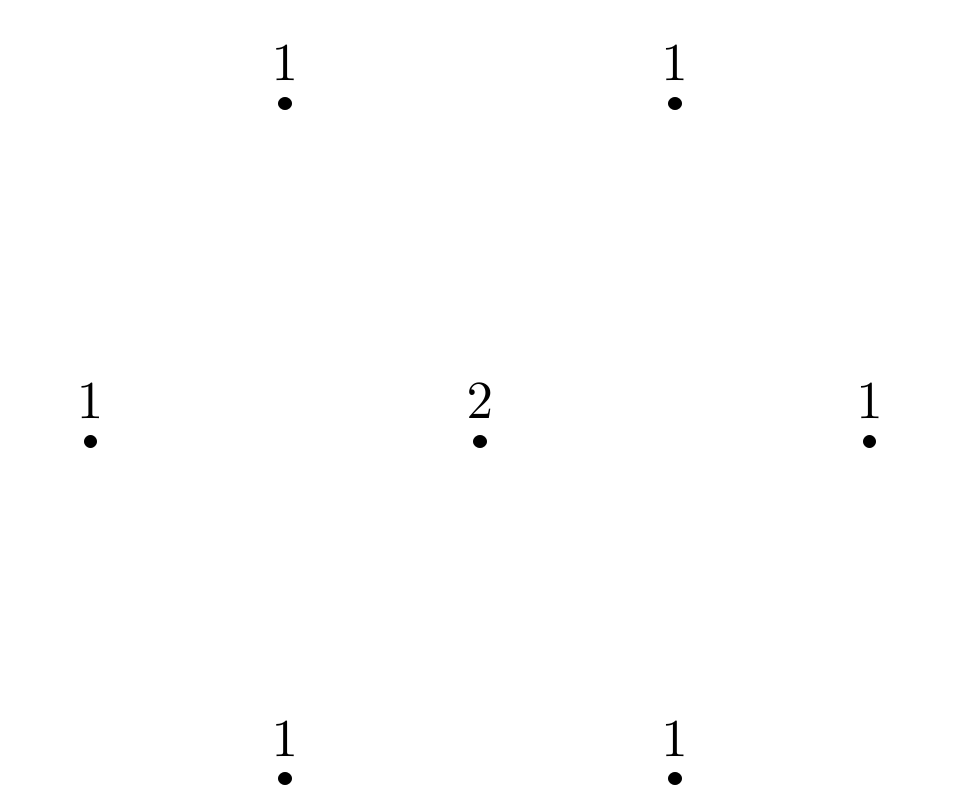

In [57]:
charPlot[1, 1]

-Graphics-
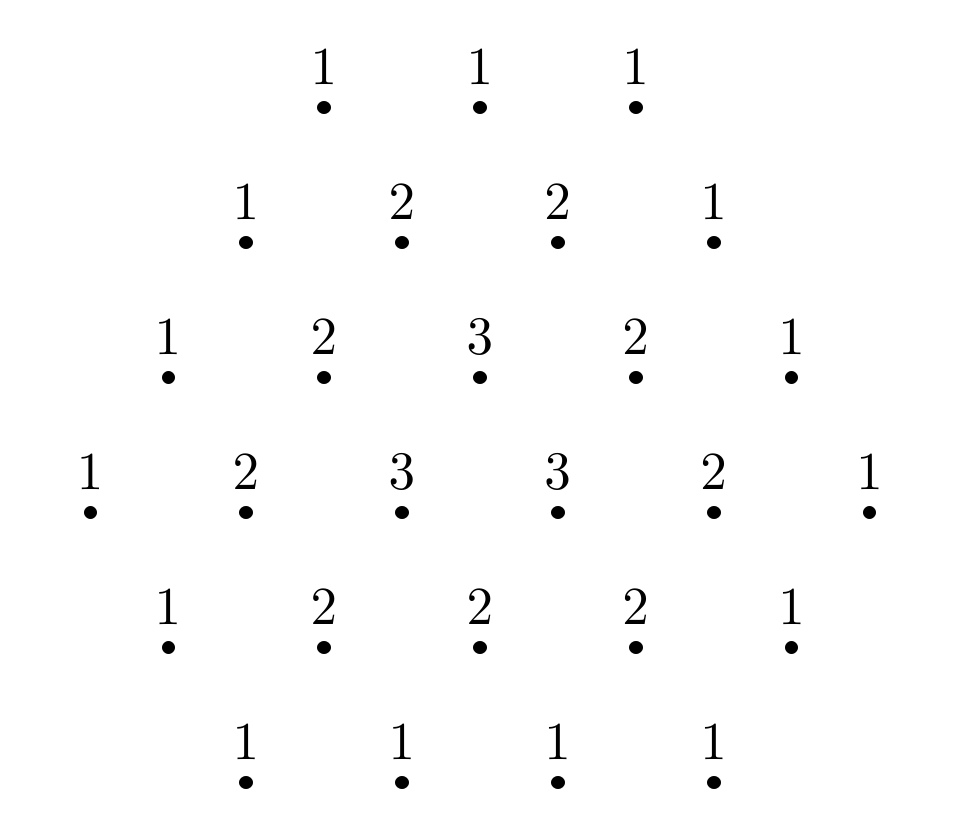

In [58]:
charPlot[3, 2]